<a href="https://colab.research.google.com/github/hassanfasih131-cpu/Crime_Pakistan/blob/feature%2FReprocessing-and-Feature-Engineering/Crime_Pakistan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Title**: Pakistan Crime Analysis and Prediction

**Data Source** : https://opendata.com.pk/dataset/crimes-reported-by-type-and-provinces-in-pakistan-2018-2020/resource/59ccb28c-7f6c-4219-a807-7a1c3ba29256


**What one Row Represents**: Each row represents the number of specific crime that took place in a specific region at a particular year.


**Target Variable**: Crime Count


**Problem Type**: Regression


**Usefulness in the Real World**: This project aims to identify regional crime patterns, predict future crime rate, and help law enforces, and researchers to plan ahead.

**Expected Data Challanges**:


*   The original dataset only covers 3 years, which limits information available
*   The original dataset contains year headings within the data.
*   Totals must be separated from regional observations
*   The dataset rquires restructuring to a long format
*   There are some missing values
*  There are empty columns that need to be removed




In [29]:
#Importing the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn


In [30]:
#Importing the dataset
from google.colab import files
uploaded=files.upload()

Saving Crimes.csv to Crimes (1).csv


In [31]:
#Loading the dataset
filename=next(iter(uploaded))
df=pd.read_csv(filename)
display(df.head(5))

,Type of Crime,Punjab,Sindh,KPK,Balochistan,Islamabad,Railways,G.B,AJK,Pakistan,Unnamed: 10,Unnamed: 11
0,2018,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Murder,4017.0,1308.0,2320.0,352.0,103.0,2.0,76.0,63.0,8241.0,NaN,NaN
2,Attempt to Murder,5093.0,1590.0,2628.0,348.0,171.0,1.0,89.0,147.0,10067.0,NaN,NaN
3,Kidnapping /Abduction,14981.0,3167.0,1188.0,269.0,123.0,3.0,38.0,291.0,20060.0,NaN,NaN
4,Dacocity,793.0,509.0,39.0,28.0,39.0,0.0,2.0,4.0,1414.0,NaN,NaN


In [32]:
#Cleaning the dataset
dataS=df.copy() #Creating a copy, to avoid original being ruined
#Removing un-important Null columns
dataS=dataS.drop(columns=["Unnamed: 10"])
dataS=dataS.drop(columns=["Unnamed: 11"])
#Year is written in row form, it needs to be swapped
#Creating a Year Column
dataS["Year"]=pd.to_numeric(dataS.iloc[:,0],errors="coerce")
dataS["Year"]=dataS["Year"].ffill()
#Removing the Year Rows
dataS=dataS.drop(0)
dataS=dataS.drop(11)
dataS=dataS.drop(22)
#Removing Total rows
dataS=dataS.drop(10)
dataS=dataS.drop(21)
dataS=dataS.drop(32)
#Reset Index
dataS=dataS.reset_index(drop=True)


In [33]:
#Removing white spaces in column names
dataS.columns = dataS.columns.str.strip()
#Restructuring it to long format
dataS2 = dataS.melt(
    id_vars=["Year", "Type of Crime"],
    var_name="Region",
    value_name="Crime Count"
)
# Remove every row that has Pakistan as region
dataS2 = dataS2[dataS2['Region'] != 'Pakistan']
display(dataS2.head(5))

,Year,Type of Crime,Region,Crime Count
0,2018.0,Murder,Punjab,4017.0
1,2018.0,Attempt to Murder,Punjab,5093.0
2,2018.0,Kidnapping /Abduction,Punjab,14981.0
3,2018.0,Dacocity,Punjab,793.0
4,2018.0,Robbery,Punjab,11128.0


In [34]:
#Replacing old table with new table
dataS=dataS2
#Printing information about the dataset
print("The dimension is ", dataS.shape,"\n")
print("The column names and datatype is: ",dataS.columns,"\n")
print("Statistics of the Data: ",dataS["Crime Count"].describe(),"\n")
#Checking for unusual values
print("There are",dataS["Crime Count"].isnull().sum()," missing values\n")
print("There are",dataS.duplicated().sum()," duplicate values\n")
print("There are",(dataS["Crime Count"]<0).sum()," negative values\n")
dataS[dataS["Crime Count"].isnull()]


The dimension is  (216, 4) 

The column names and datatype is:  Index(['Year', 'Type of Crime', 'Region', 'Crime Count'], dtype='object') 

Statistics of the Data:  count       215.000000
mean      11005.800000
std       48594.574046
min           0.000000
25%          54.500000
50%         319.000000
75%        2224.000000
max      401465.000000
Name: Crime Count, dtype: float64 

There are 1  missing values

There are 0  duplicate values

There are 0  negative values



,Year,Type of Crime,Region,Crime Count
210,2020.0,Dacocity,AJK,NaN


1- This column bar chart shows that the crime rate has increased over the years

Text(0, 0.5, 'Total Count')

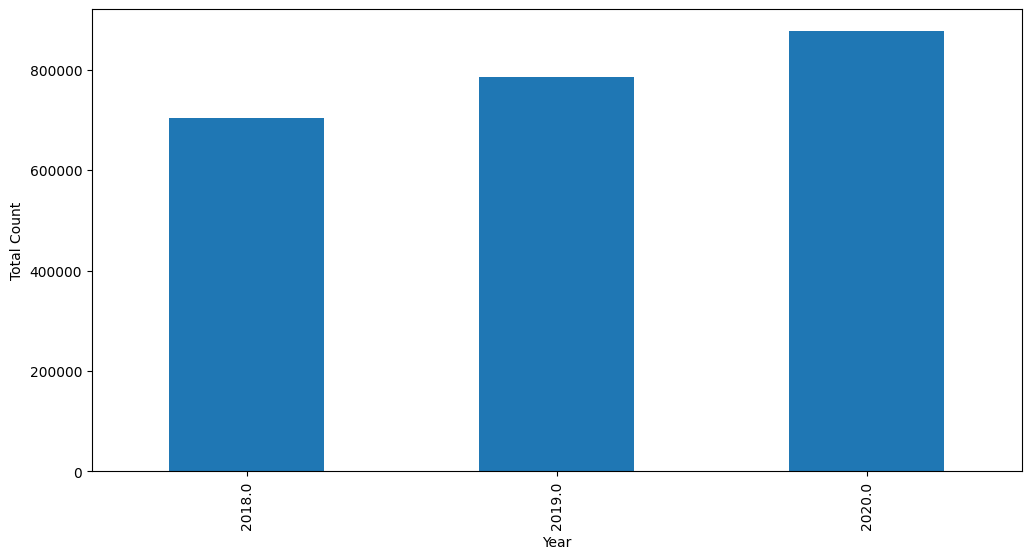

In [35]:
crime_counts = dataS.groupby("Year")["Crime Count"].sum().sort_values()
plt.figure(figsize=(12, 6))
crime_counts.plot(kind="bar")
plt.xlabel("Year")
plt.ylabel("Total Count")


2- Amongst Theft Crimes, Petty/Other Theft is the most common type of theft, followed by Property Theft(combining Burglary, Robbery and Dacocity) and then Livestock Theft.



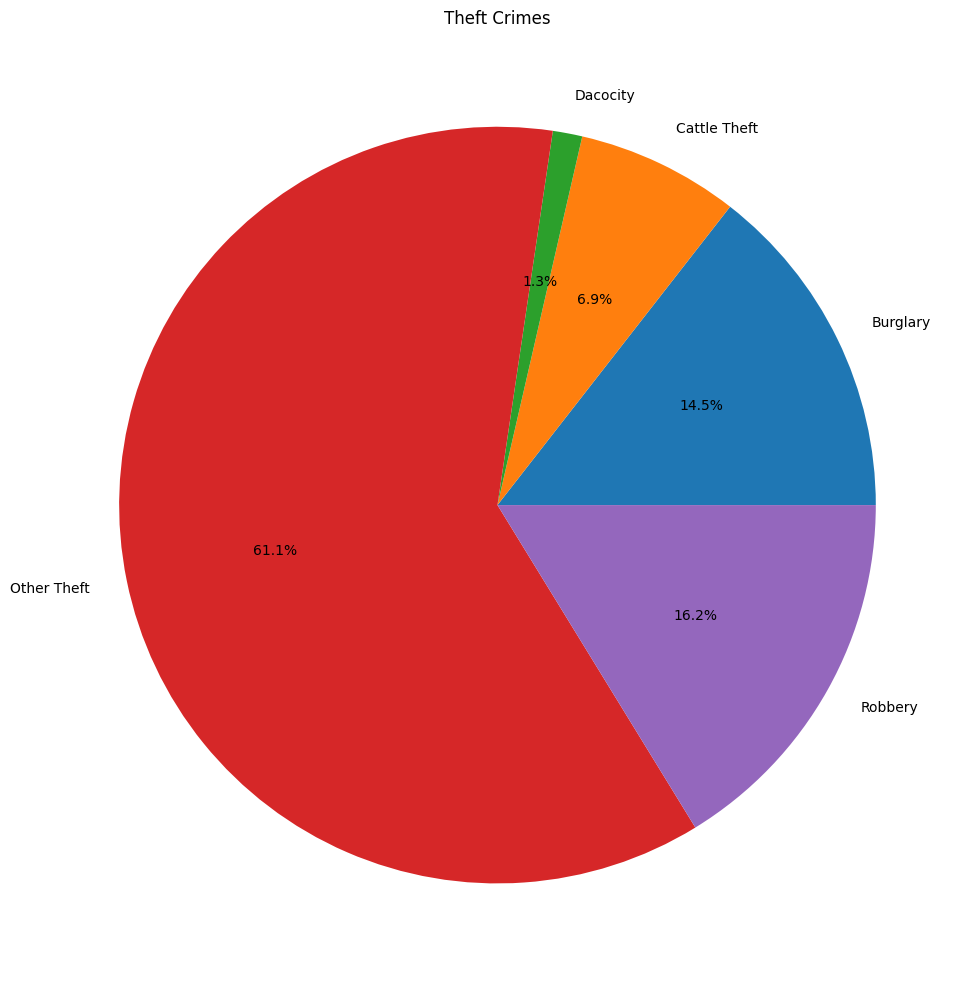

In [36]:
filtered_data = dataS[dataS["Type of Crime"].isin(["Cattle Theft","Burglary", "Robbery", "Dacocity","Other Theft"])]
crime_shares = filtered_data.groupby("Type of Crime")["Crime Count"].sum()
plt.figure(figsize=(10, 10))
plt.pie(
    crime_shares,
    labels=crime_shares.index,
    autopct="%1.1f%%",
)
plt.title("Theft Crimes")
plt.tight_layout()
plt.show()


3- Majority of the crimes took place in the main Provinces, with Punjab being the one that is most affected. Territories like Gilgit Baltistan, Azad Jamu and Kashmir and the Special Jurisdiction (Railways) had the least amount of crimes

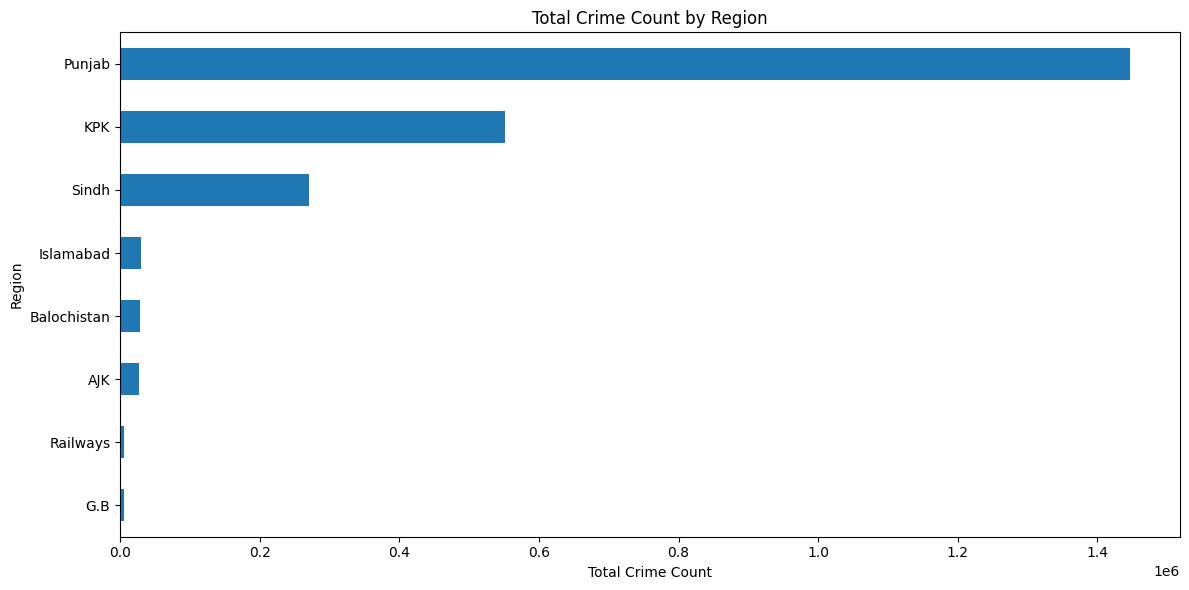

In [37]:
region_counts = dataS.groupby("Region")["Crime Count"].sum().sort_values(ascending=True)
plt.figure(figsize=(12, 6))
region_counts.plot(kind="barh")
plt.title("Total Crime Count by Region")
plt.xlabel("Total Crime Count")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

4- The crime rate increased by alot in Azad Jammu and Kashmir from 2019 to 2020, increased slightly in Gilgit Baltistan and decreased in Pakistan Railways

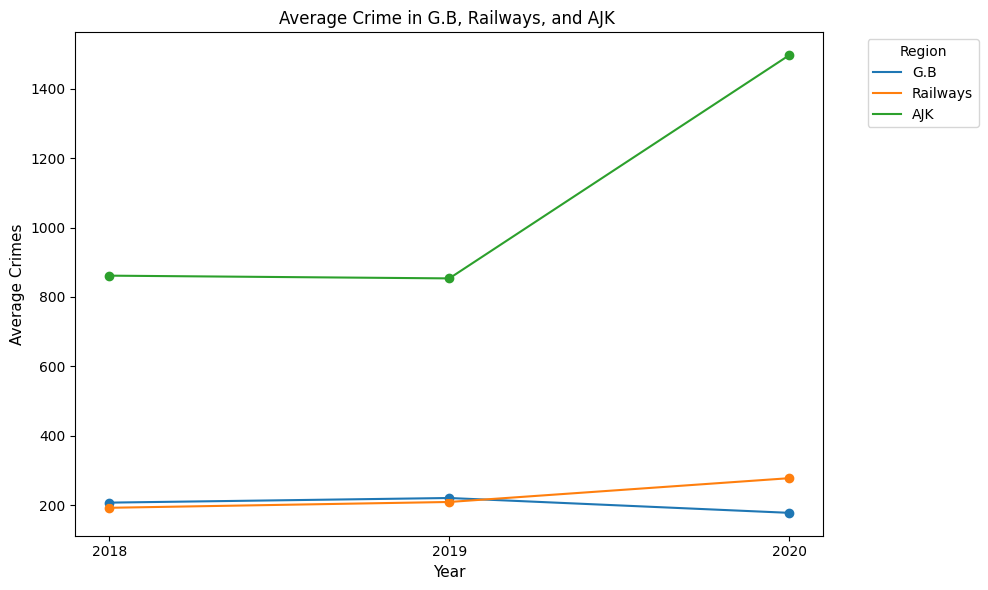

In [38]:
target= ["G.B", "Railways", "AJK"]
filtered_dataS = dataS[dataS["Region"].isin(target)]
yearly_region = filtered_dataS.groupby(["Year", "Region"])["Crime Count"].mean().reset_index()
plt.figure(figsize=(10, 6))
for i in target:
    region_data = yearly_region[yearly_region["Region"] == i]
    if not region_data.empty:
        line = plt.plot(
            region_data["Year"],
            region_data["Crime Count"],
            label=i,
        )
        plt.scatter(
            region_data["Year"],
            region_data["Crime Count"],
            color=line[0].get_color(),
        )
plt.xlabel("Year", fontsize=11)
plt.ylabel("Average Crimes", fontsize=11)
plt.title("Average Crime in G.B, Railways, and AJK ")
plt.xticks(yearly_region["Year"].unique())
plt.legend(title="Region", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

5- Kidnapping is the most common Violent crime, followed by Attempt to Murder and then Murder

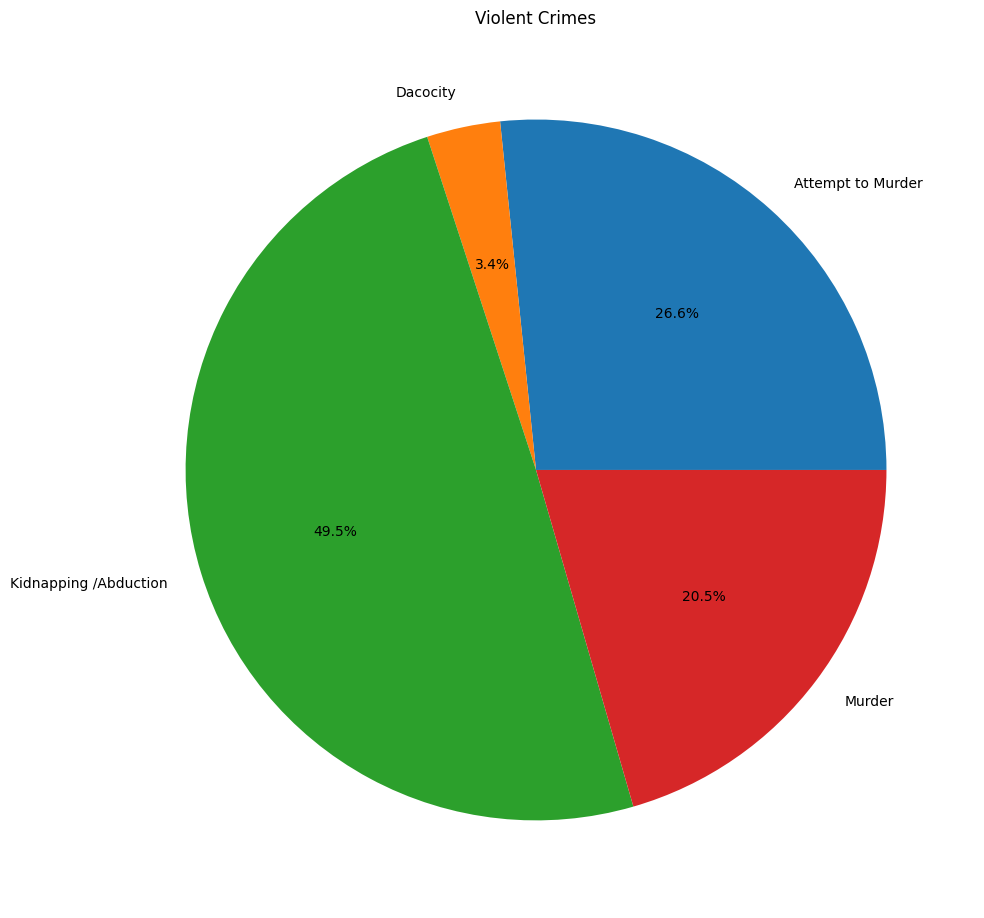

In [39]:
violence = dataS[dataS["Type of Crime"].isin(["Murder","Attempt to Murder","Kidnapping /Abduction","Dacocity"])]
crime_shares2 = violence.groupby("Type of Crime")["Crime Count"].sum()
plt.figure(figsize=(10, 10))
plt.pie(
    crime_shares2,
    labels=crime_shares2.index,
    autopct="%1.1f%%",
)
plt.title("Violent Crimes")
plt.tight_layout()
plt.show()

In [40]:
#Removing the NA value rows
dataS=dataS.dropna()
print("Successfully removed the rows with missing values\n")
print("There are now",dataS["Crime Count"].isnull().sum()," missing values\n")

Successfully removed the rows with missing values

There are now 0  missing values



In [41]:
#Preventing Data leakage/Train test split
from sklearn.model_selection import train_test_split
x=dataS.drop(columns='Crime Count') #predictor
y=dataS['Crime Count'] #Target
X_train, X_test, y_train, y_test=train_test_split(x,y,test_size=0.2,random_state=42)

Feature 1: This feature distinguishes if the Crime is Violent or not in binary form. It is useful as we can split the data based on its severity, preventing the model from treating less dangerous crimes like petty theft the same as a serious crime such as Murder.

Feature 2: This feature seperates Region depending on Type. Crime rate is overwhelming in the Main Provinces especially in Punjab compared to Pakistan's Territories and Capital. This feature helps the model account for base volume depending on the region region.

In [58]:
#Creating the 2 Useful Features
def Engin_Features(a):
  datanew=a.copy()
  violence=['Murder','Attempt to Murder','Kidnapping /Abduction','Dacocity'] #Violent crimes
  special=['Islamabad','Railways','G.B','AJK'] #Pakistan's territories and Capital
  datanew["Violent Crime"]=dataS['Type of Crime'].isin(violence).astype(int) #Checks if the Crime is Violent
  #Seperates the Main Provinces with other regions
  datanew['Region Type']=datanew['Region'].apply(lambda x: 'Territory or Special Jurisdiction' if x in special else 'Major Province' )
  return datanew
#Applying features on X_train and X_test
X_train=Engin_Features(X_train)
X_test=Engin_Features(X_test)

In [59]:
#Column Transformer and Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
numeric=['Year','Violent Crime']
categorical=['Type of Crime', 'Region Type']
#Numeric Pipeline
numeric_transformer=Pipeline(steps=[('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())])
#Categorical Pipeline
categorical_transformer=Pipeline(
    steps=[
        ('imputer',SimpleImputer(strategy='constant',fill_value='Unknown')),
        ('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False),
         )
    ]
)
#Combining both
preprocessor=ColumnTransformer(
    transformers=[
        ('num',numeric_transformer,numeric),
        ('cat',categorical_transformer,categorical)
    ]
)
#transforming Training data
X_trainp=preprocessor.fit_transform(X_train)
X_testp=preprocessor.transform(X_test)